# 04 · MSL RAD: understand radiation on the Mars surface

**Questions**
1. What is in the record: units, cadence, gaps, quality flags?
2. What does the dose rate do over time: the slow change with the solar cycle, the daily (diurnal) cycle, and the May 2024 solar storm?
3. Do the numbers agree with the published reference values?
4. Detector B (silicon) or detector E (tissue-equivalent plastic): which one should drive the dose counter?

**Inputs:** `data/raw/msl_rad/<year>/*.cdf` (real data, NASA/JPL Curiosity RAD level 2; Hassler et al.).
**Outputs:** `data/processed/msl_rad_hourly.parquet`, `data/processed/msl_rad_daily.parquet`, figures `reports/figures/04_*.png`.

In [1]:
import sys
sys.path.insert(0, "../ml")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sol_ml.nbutil import *
from sol_ml.data import msl_rad

rng = setup()
pd.set_option("display.width", 220)
warnings.filterwarnings("ignore")

obs = msl_rad.load_all()
print(len(obs), "observations,", obs.time.min(), "to", obs.time.max(), "| unreadable files:", len(obs.attrs["skipped"]))
hourly, daily = msl_rad.to_hourly(obs), msl_rad.to_daily(obs)
hourly.reset_index().to_parquet(PROCESSED / "msl_rad_hourly.parquet", index=False)
daily.reset_index().to_parquet(PROCESSED / "msl_rad_daily.parquet", index=False)
print("hourly", hourly.shape, "| daily", daily.shape)
obs.head(3)

89038 observations, 2024-01-01 00:11:02 to 2026-11-11 16:37:16 | unreadable files: 0
hourly (25097, 5) | daily (1046, 6)


,time,dose_b,dose_b_rtg,dose_e,flag,alive_s,good
0,2024-01-01 00:11:02,179.521652,120.689606,177.889984,,928.514038,True
1,2024-01-01 00:28:08,195.086411,136.254364,180.215576,,928.339294,True
2,2024-01-01 00:45:14,191.751877,132.921722,184.351288,,927.465454,True


## 1. Units, cadence, gaps, flags

In [2]:
step = obs.time.diff().dt.total_seconds() / 60
per_day = obs.set_index("time").dose_e.resample("D").count()
all_days = pd.date_range(obs.time.min().normalize(), obs.time.max().normalize())
missing_days = all_days.difference(daily.index)
gap_runs = (pd.Series(missing_days).diff().dt.days != 1).cumsum() if len(missing_days) else pd.Series(dtype=int)
summary = pd.Series({
    "unit (from the CDF attributes)": "uGy/day",
    "median minutes between observations": round(step.median(), 1),
    "95th percentile minutes between observations": round(step.quantile(0.95), 1),
    "median observations per day": per_day[per_day > 0].median(),
    "calendar days in range": len(all_days),
    "days without any data": len(missing_days),
    "longest run of missing days": int(gap_runs.value_counts().max()) if len(missing_days) else 0,
    "hours with data (share of all hours)": round(hourly.dose_e.notna().mean(), 3),
    "observations with a quality flag": f"{(~obs.good).mean():.1%}",
})
print(obs.flag.replace("", "(good)").value_counts().to_string(), "\n")
print("years on disk:", sorted(obs.time.dt.year.unique()))
summary.to_frame("value")

flag
(good)            86253
Cmds               2508
High Temp           272
Cmds,High Temp        3
Cary                  1
Eddie,Cmds            1 

years on disk: [np.int32(2024), np.int32(2025), np.int32(2026)]


,value
unit (from the CDF attributes),uGy/day
median minutes between observations,17.1
95th percentile minutes between observations,17.1
median observations per day,85.0
calendar days in range,1046
days without any data,0
longest run of missing days,0
hours with data (share of all hours),0.996
observations with a quality flag,3.1%


## 2. The full record

,dose_e,dose_b_rtg,dose_b,days
date,,,,
2024,161.7,113.1,171.6,366
2025,156.8,109.7,167.5,365
2026,175.2,122.8,180.0,315


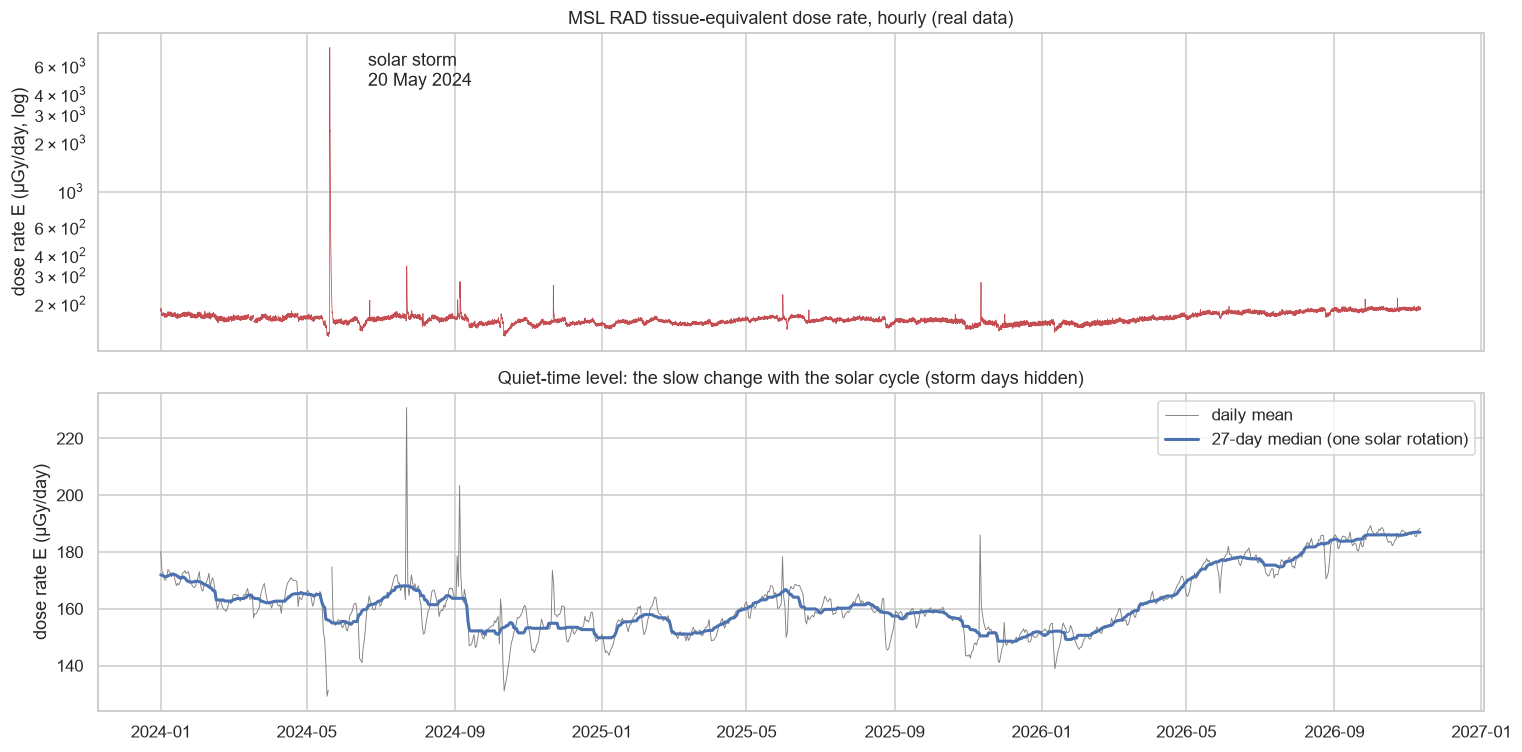

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(hourly.index, hourly.dose_e, lw=0.5, color="#c44e52")
axes[0].set(yscale="log", ylabel="dose rate E (µGy/day, log)", title="MSL RAD tissue-equivalent dose rate, hourly (real data)")
storm = hourly.dose_e.idxmax()
axes[0].annotate(f"solar storm\n{storm:%d %b %Y}", (storm, hourly.dose_e.max()), xytext=(25, -25), textcoords="offset points",
                 arrowprops=dict(arrowstyle="->"))
quiet_daily = daily.dose_e.where(daily.dose_e < 2 * daily.dose_e.median())
axes[1].plot(daily.index, quiet_daily, lw=0.6, color="grey", label="daily mean")
axes[1].plot(daily.index, quiet_daily.rolling(27, min_periods=10, center=True).median(), lw=2, color="#4c72b0", label="27-day median (one solar rotation)")
axes[1].set(ylabel="dose rate E (µGy/day)", title="Quiet-time level: the slow change with the solar cycle (storm days hidden)")
axes[1].legend()
savefig("04_full_record");
by_year = daily.groupby(daily.index.year)[["dose_e", "dose_b_rtg", "dose_b"]].median().round(1)
by_year["days"] = daily.groupby(daily.index.year).size()
by_year

## 3. The daily (diurnal) cycle
A Mars day (sol) is 24 h 39.6 min, so the cycle has to be read in **Mars local solar time**; against Earth's UTC clock it smears out.

peak-to-trough: 3.4 % of the mean (max at 16 h, min at 05 h local)
hour-to-hour noise of a quiet hourly value: 1.8 %


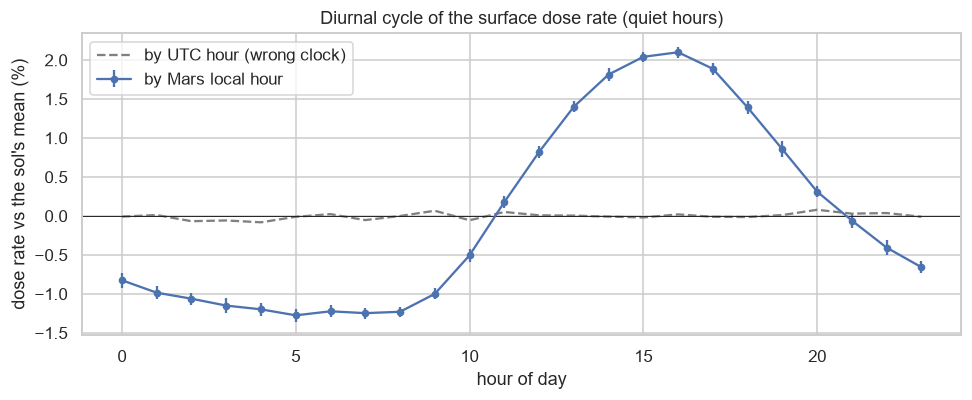

In [4]:
q = hourly[(hourly.dose_e < 1.5 * hourly.dose_e.rolling(168, min_periods=24).median())].copy()
q["rel"] = q.dose_e / q.dose_e.rolling(25, min_periods=12, center=True).mean() - 1        # relative to that sol's mean
by_local = q.groupby(np.floor(q.local_hour).astype(int)).rel.agg(["mean", "sem"]) * 100
by_utc = q.groupby(q.index.hour).rel.mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar(by_local.index, by_local["mean"], yerr=1.96 * by_local["sem"], marker="o", ms=4, label="by Mars local hour")
ax.plot(by_utc.index, by_utc.values, color="grey", ls="--", label="by UTC hour (wrong clock)")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="hour of day", ylabel="dose rate vs the sol's mean (%)", title="Diurnal cycle of the surface dose rate (quiet hours)")
ax.legend()
savefig("04_diurnal_cycle");
amplitude = (by_local["mean"].max() - by_local["mean"].min())
print("peak-to-trough: %.1f %% of the mean (max at %02d h, min at %02d h local)" % (amplitude, by_local["mean"].idxmax(), by_local["mean"].idxmin()))
print("hour-to-hour noise of a quiet hourly value: %.1f %%" % (100 * q.rel.std()))

## 4. The 20 May 2024 solar storm

,value
quiet level before (µGy/day),148.6
peak E (µGy/day),8378.0
peak time (UTC),2024-05-20 06:15:19
peak / quiet,56.4
first hour above 2x quiet,2024-05-20 05:00:00
last hour above 2x quiet,2024-05-21 12:00:00
hours above 2x quiet,32
extra dose from the storm (µGy),1714.0
equal to this many quiet days,11.5


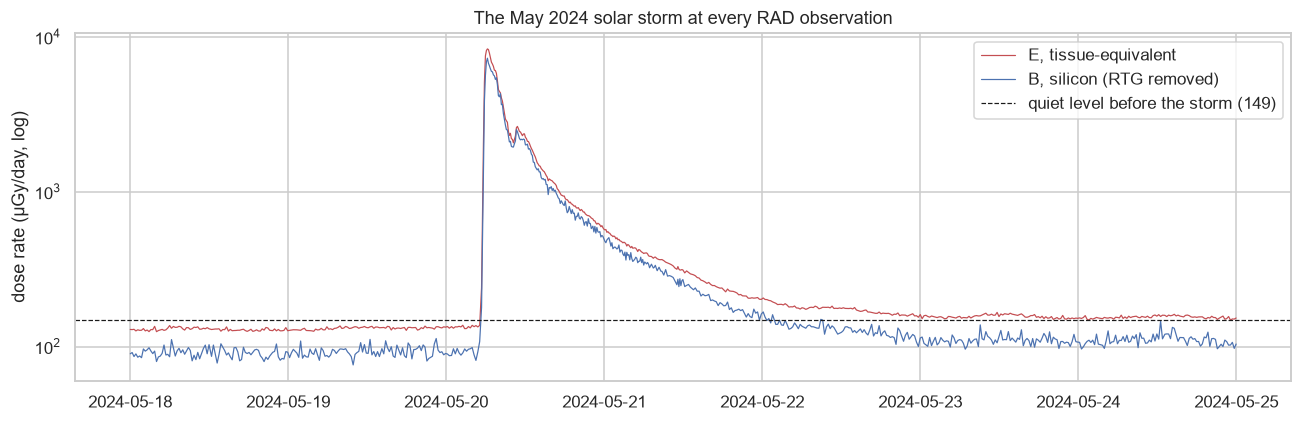

In [5]:
win = slice("2024-05-18", "2024-05-24")
ev_obs = obs[obs.good].set_index("time").loc[win]
base = hourly.dose_e.loc["2024-05-13":"2024-05-19"].median()
ev = hourly.dose_e.loc[win]
above = ev[ev > 2 * base]
excess = (ev - base).clip(lower=0).loc[above.index.min(): above.index.max()].sum() / 24     # µGy (rate in µGy/day x 1 h)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ev_obs.index, ev_obs.dose_e, lw=0.8, color="#c44e52", label="E, tissue-equivalent")
ax.plot(ev_obs.index, ev_obs.dose_b_rtg, lw=0.8, color="#4c72b0", label="B, silicon (RTG removed)")
ax.axhline(base, color="k", ls="--", lw=0.8, label=f"quiet level before the storm ({base:.0f})")
ax.set(yscale="log", ylabel="dose rate (µGy/day, log)", title="The May 2024 solar storm at every RAD observation")
ax.legend()
savefig("04_may2024_storm");
peak = ev_obs.dose_e.idxmax()
pd.Series({"quiet level before (µGy/day)": round(base, 1), "peak E (µGy/day)": round(ev_obs.dose_e.max(), 0), "peak time (UTC)": peak,
           "peak / quiet": round(ev_obs.dose_e.max() / base, 1), "first hour above 2x quiet": above.index.min(), "last hour above 2x quiet": above.index.max(),
           "hours above 2x quiet": len(above), "extra dose from the storm (µGy)": round(excess, 0),
           "equal to this many quiet days": round(excess / base, 1)}).to_frame("value")

In [6]:
# Other departures from the quiet level: daily peak against the 27-day median.
level = daily.dose_e.rolling(27, min_periods=10).median().shift(1)
ratio = (daily.dose_e_max / level).dropna().sort_values(ascending=False)
events = pd.DataFrame({"daily_peak": daily.dose_e_max.loc[ratio.index[:10]].round(0), "x_quiet_level": ratio.head(10).round(2)})
low = (daily.dose_e / level).dropna().sort_values().head(5).round(2)
print("deepest drops (Forbush decreases), daily mean / quiet level:", low.to_dict())
events

deepest drops (Forbush decreases), daily mean / quiet level: {Timestamp('2024-05-18 00:00:00'): 0.78, Timestamp('2024-05-19 00:00:00'): 0.8, Timestamp('2024-05-17 00:00:00'): 0.85, Timestamp('2024-10-12 00:00:00'): 0.86, Timestamp('2024-10-13 00:00:00'): 0.88}


,daily_peak,x_quiet_level
date,,
2024-05-20,8378.0,50.86
2024-05-21,571.0,3.46
2024-06-22,332.0,2.14
2024-07-23,349.0,2.11
2025-11-11,286.0,1.86
2024-09-05,304.0,1.86
2024-11-21,263.0,1.72
2026-10-23,315.0,1.69
2026-09-26,305.0,1.66


## 5. Sanity check against the published values

In [7]:
quiet_days = daily[daily.dose_e_max < 1.3 * level]
ref = pd.DataFrame({
    "this record (median quiet day)": [quiet_days.dose_e.median() / 1000, quiet_days.dose_b_rtg.median() / 1000, quiet_days.dose_b.median() / 1000],
    "Hassler et al. 2014 (2012-13)": [0.21, np.nan, 0.16]},
    index=["E tissue-equivalent (mGy/day)", "B silicon, RTG removed (mGy/day)", "B silicon, total (mGy/day)"]).round(3)
ref

,this record (median quiet day),Hassler et al. 2014 (2012-13)
E tissue-equivalent (mGy/day),0.160,0.21
"B silicon, RTG removed (mGy/day)",0.112,NaN
"B silicon, total (mGy/day)",0.170,0.16


## 6. Detector B or detector E?

,value
median E / B(RTG removed),1.429
IQR of the ratio,1.420 - 1.438
"hourly correlation, all hours (log)",0.939
"hourly correlation, quiet hours",0.883
relative hourly noise E (quiet),7.2%
relative hourly noise B RTG-removed (quiet),8.4%
storm peak E / B(RTG removed),1.15


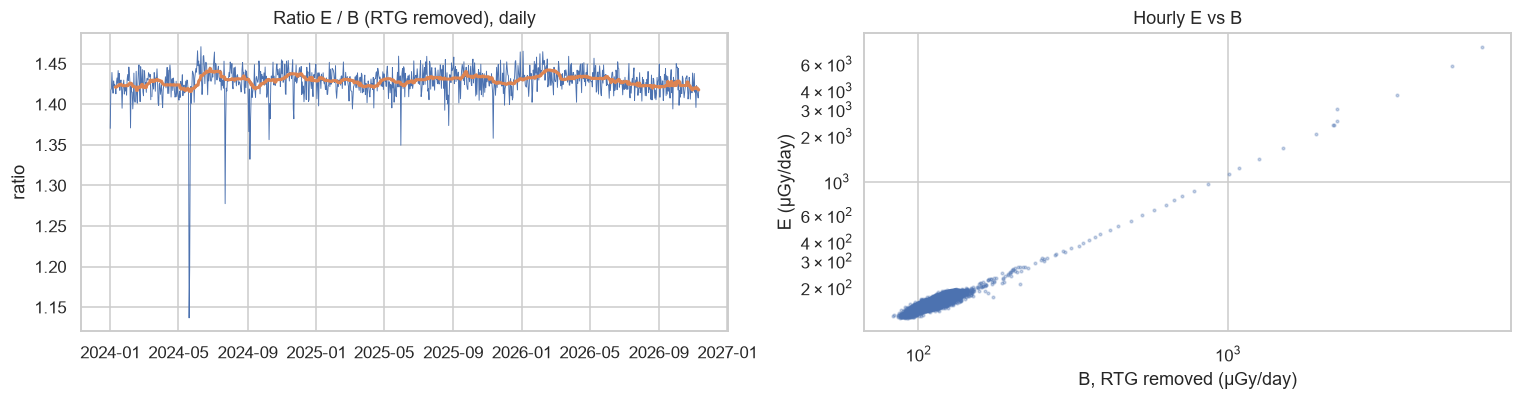

In [8]:
r = (daily.dose_e / daily.dose_b_rtg).where(daily.hours >= 12)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(r.index, r, lw=0.6); axes[0].plot(r.index, r.rolling(27, min_periods=10).median(), lw=2)
axes[0].set(title="Ratio E / B (RTG removed), daily", ylabel="ratio")
axes[1].scatter(hourly.dose_b_rtg, hourly.dose_e, s=3, alpha=0.3)
axes[1].set(xscale="log", yscale="log", xlabel="B, RTG removed (µGy/day)", ylabel="E (µGy/day)", title="Hourly E vs B")
savefig("04_b_vs_e");
quiet_h = hourly[hourly.dose_e < 1.5 * hourly.dose_e.median()]
pd.Series({"median E / B(RTG removed)": round(r.median(), 3), "IQR of the ratio": f"{r.quantile(.25):.3f} - {r.quantile(.75):.3f}",
           "hourly correlation, all hours (log)": round(np.corrcoef(np.log(hourly.dropna().dose_b_rtg.clip(lower=1)), np.log(hourly.dropna().dose_e))[0, 1], 3),
           "hourly correlation, quiet hours": round(quiet_h[["dose_b_rtg", "dose_e"]].corr().iloc[0, 1], 3),
           "relative hourly noise E (quiet)": f"{quiet_h.dose_e.std() / quiet_h.dose_e.mean():.1%}",
           "relative hourly noise B RTG-removed (quiet)": f"{quiet_h.dose_b_rtg.std() / quiet_h.dose_b_rtg.mean():.1%}",
           "storm peak E / B(RTG removed)": round(ev_obs.dose_e.max() / ev_obs.dose_b_rtg.max(), 2)}).to_frame("value")

## Findings

1. **The record is clean and continuous.** 89,038 observations over 1,046 days (1 Jan 2024 to 11 Nov 2026), one about every 17 minutes, no day without data,
   99.6 % of hours covered, 3.1 % of observations flagged (mostly `Cmds`, dropped here). 2025 was downloaded as well, so the three years connect.
2. **Units are µGy/day, as the plan assumed.** A quiet day is 0.160 mGy/day in tissue-equivalent plastic (E) and 0.170 mGy/day in silicon (B, total),
   0.112 mGy/day with the RTG removed. Hassler et al. measured 0.21 (E) in 2012–13. Today's E is 24 % lower, which is expected: 2024–26 is near solar maximum,
   when the Sun shields Mars from more galactic cosmic rays. The yearly median moved from 162 (2024) to 157 (2025) to 175 µGy/day (2026).
3. **The diurnal cycle is real but small: 3.4 % peak to trough**, highest around 16 h and lowest around 05 h Mars local time (the atmosphere is thinner in the afternoon).
   It only shows on the Mars clock; by UTC hour it averages out. The hour-to-hour noise of a quiet hourly value is 1.8 %, so the cycle is about twice the noise.
4. **The 20 May 2024 storm is unmistakable.** E peaked at 8,378 µGy/day at 06:15 UTC, **56 times** the quiet level of the week before, stayed above twice the quiet level for 32 hours,
   and added about 1,700 µGy, the same as 11.5 quiet days. (The "about 8,100 µGy" in `docs/DATASETS.md` matches the peak dose *rate*, not the dose received.)
   The three days before the storm were 15–22 % *below* normal: a Forbush decrease, the usual precursor of a coronal mass ejection.
5. **Smaller events exist**: 21 May 2024 (3.5x, the storm's tail), 22 Jun 2024 (2.1x), 23 Jul 2024 (2.1x), then several at 1.6–1.9x.
   A storm alarm has to decide whether these count; notebook 05 treats only 20–21 May 2024 as a must-catch event.
6. **B and E tell the same story.** Their ratio is very stable (E / B with RTG removed = 1.43, IQR 1.42–1.44) and they correlate 0.94 hour by hour.
   In the storm the ratio dropped to 1.15, because storm protons are less penetrating than cosmic rays.

## Decision

**Detector E (tissue-equivalent plastic) drives both the dose counter and the storm alarm**, as the team planned.
It is the closest to human tissue, it needs no RTG correction, and its hourly noise is slightly lower than B's (7.2 % vs 8.4 % across the whole record).
B with the RTG removed is kept as a cross-check: if E and B disagree by more than their usual ratio, the reading is suspect.

**For notebook 05:** work on the **hourly** table (99.6 % coverage), compare each hour with a trailing 7-day baseline (it absorbs the slow solar-cycle change of about ±10 % per year),
  and test whether removing the 3.4 % diurnal cycle on the Mars clock changes anything.

**Rejected:** total B (it contains the rover's own RTG, about a third of the signal); UTC-hour seasonality (wrong clock).

**Known limits:** this is the Mars *surface* under about 20 g/cm² of CO2 atmosphere, during solar maximum. Transit to Mars has no atmosphere and a higher rate (1.84 mSv/day, Zeitlin et al. 2013),
and a solar-minimum mission would see more cosmic rays and fewer storms. One large storm in three years is a single example, not a sample.